# Demo D3.1 · Classification that a CRO can sign — probabilities, thresholds and the right metrics
**Horizon Gulf Bank · Project MIZAN** · CAIP AIP-210 · Certified AI Practitioner · Day 3 · ⏱ 40 min · **Demo · complete solution**

Why 92% accuracy can be a useless credit model, and how ROC, precision–recall and a cost matrix pick the decision threshold.

### Scenario
**Horizon Gulf Bank (HGB)** is a fictional UAE retail bank with 250,000 customers. Its Board approved **Project MIZAN** — an AI decisioning platform covering credit, fraud, collateral valuation, cash logistics, customer retention and document automation. You are a junior ML practitioner in the MIZAN squad.

The credit feature pipeline from Day 1 is ready. The CRO asks three questions: *How good is the model? Where do we set the cut-off? What does each mistake cost us?* This demo answers them.

In [1]:
# ── Project MIZAN course setup ─ run this cell first ──────────────────────────
from pathlib import Path
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the course root (the folder that contains data/generate_data.py) from wherever this notebook lives
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "generate_data.py").exists())
DATA = ROOT / "data"          # raw synthetic datasets (read-only)
CKPT = ROOT / "checkpoints"   # hand-off artefacts between labs (lets you start any lab fresh)
CKPT.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": .3})
RNG = 42
print("Course root:", ROOT)

Course root: C:\Users\Pushkar\Downloads\CAIP-AIP210-FINANCIAL-SERVICES-TRAINER-PACK\CAIP-AIP210-TopTier-Courseware


## 1 · Load the Day 1 contract and fit logistic regression

We reuse Day 1’s feature table and fitted preprocessor — no re-engineering. Logistic regression squashes a linear score through the **sigmoid** into a probability of default (PD).

In [2]:
import joblib, json
from sklearn.base import clone
feat = pd.read_parquet(CKPT / "loan_features.parquet")
spec = json.loads((CKPT / "loan_feature_spec.json").read_text())
preprocessor = joblib.load(CKPT / "loan_preprocessor.joblib")      # fitted on train in Lab L1.2
TARGET = spec["target"]
train, valid, test = (feat[feat.split == s] for s in ["train", "valid", "test"])
print({s: len(d) for s, d in zip(["train", "valid", "test"], [train, valid, test])}, "| honest baseline AUC from L1.2:", spec["honest_valid_auc"])

{'train': 207705, 'valid': 45994, 'test': 46301} | honest baseline AUC from L1.2: 0.8292


validation AUC: 0.829


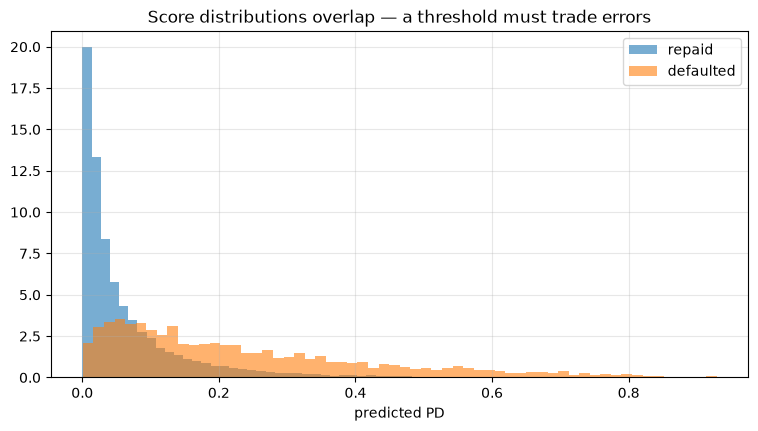

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
logit = Pipeline([("prep", clone(preprocessor)), ("clf", LogisticRegression(max_iter=2000))]).fit(train, train[TARGET])
p = logit.predict_proba(valid)[:, 1]
print("validation AUC:", round(roc_auc_score(valid[TARGET], p), 3))
plt.hist(p[valid[TARGET] == 0], bins=60, alpha=.6, density=True, label="repaid")
plt.hist(p[valid[TARGET] == 1], bins=60, alpha=.6, density=True, label="defaulted")
plt.xlabel("predicted PD"); plt.legend(); plt.title("Score distributions overlap — a threshold must trade errors"); plt.show()

## 2 · The accuracy paradox

Predicting **‘nobody defaults’** is 93% accurate and approves every bad loan. At the default 0.5 threshold our model is barely more accurate but catches only a sliver of defaulters. Accuracy is the wrong metric for rare events.

always-approve accuracy: 0.9325
model @0.5 accuracy   : 0.9354


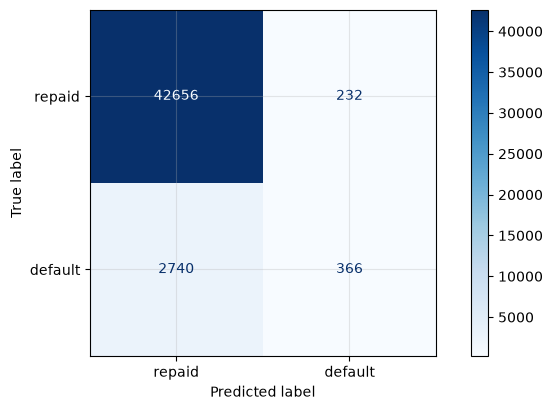

              precision    recall  f1-score   support

      repaid      0.940     0.995     0.966     42888
     default      0.612     0.118     0.198      3106

    accuracy                          0.935     45994
   macro avg      0.776     0.556     0.582     45994
weighted avg      0.918     0.935     0.914     45994



In [4]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
y = valid[TARGET].to_numpy()
print("always-approve accuracy:", round(accuracy_score(y, np.zeros_like(y)), 4))
yhat = (p >= 0.5).astype(int)
print("model @0.5 accuracy   :", round(accuracy_score(y, yhat), 4))
ConfusionMatrixDisplay(confusion_matrix(y, yhat), display_labels=["repaid", "default"]).plot(cmap="Blues"); plt.show()
print(classification_report(y, yhat, target_names=["repaid", "default"], digits=3))

## 3 · ROC and precision–recall curves

Instead of one threshold, sweep them all. **ROC** plots TPR vs FPR — AUC is the probability a random defaulter scores above a random good borrower. Under heavy imbalance the **PR curve** is more honest: its baseline is the default rate, not 0.5.

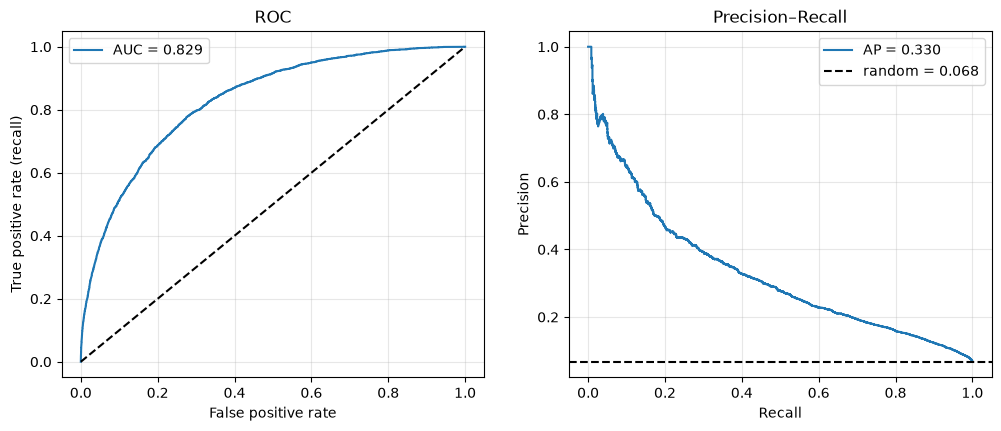

In [5]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
fpr, tpr, _ = roc_curve(y, p); prec, rec, _ = precision_recall_curve(y, p)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y, p):.3f}"); ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC")
ax[1].plot(rec, prec, label=f"AP = {average_precision_score(y, p):.3f}"); ax[1].axhline(y.mean(), color="k", ls="--", label=f"random = {y.mean():.3f}")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall"); [a.legend() for a in ax]; plt.show()

## 4 · Pick the threshold with a cost matrix

Each mistake has a price. A **false negative** (approve a defaulter) costs the loss amount. A **false positive** (reject a good borrower) costs the margin we would have earned — roughly 3% of the amount per year. We choose the threshold that **minimises total cost**.

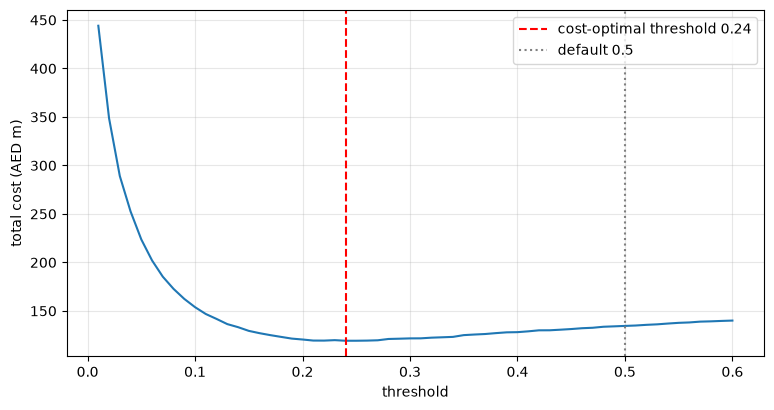

approval rate at 0.24: 92.3% | cost saving vs 0.5: AED 15.3m


In [6]:
fn_cost = valid.loss_amount_aed.to_numpy()                                    # realised loss if we approve a defaulter
fp_cost = 0.03 * valid.loan_amount_aed.to_numpy() * np.maximum(valid.tenure_months.to_numpy(), 12) / 12   # forgone margin
ths = np.linspace(0.01, 0.6, 60)
cost = [((p < t) & (y == 1)) @ fn_cost + ((p >= t) & (y == 0)) @ fp_cost for t in ths]
best = ths[int(np.argmin(cost))]
plt.plot(ths, np.array(cost) / 1e6); plt.axvline(best, color="r", ls="--", label=f"cost-optimal threshold {best:.2f}"); plt.axvline(.5, color="grey", ls=":", label="default 0.5")
plt.xlabel("threshold"); plt.ylabel("total cost (AED m)"); plt.legend(); plt.show()
print(f"approval rate at {best:.2f}: {(p < best).mean():.1%} | cost saving vs 0.5: AED {(cost[np.argmin(np.abs(ths - .5))] - min(cost)) / 1e6:,.1f}m")

## 5 · class_weight — what it does (and doesn’t) do

`class_weight='balanced'` up-weights defaulters during training. Ranking (AUC) barely changes, but probabilities are **inflated** — the model is no longer calibrated as a PD. Use it for decisions, not for IFRS 9 provisioning, unless you recalibrate.

In [7]:
bal = Pipeline([("prep", clone(preprocessor)), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]).fit(train, train[TARGET])
pb = bal.predict_proba(valid)[:, 1]
print(pd.DataFrame({"unweighted": [roc_auc_score(y, p), p.mean()], "balanced": [roc_auc_score(y, pb), pb.mean()]},
                   index=["AUC", "mean predicted PD"]).round(3))
print("actual default rate:", round(y.mean(), 3))

                   unweighted  balanced
AUC                     0.829     0.829
mean predicted PD       0.078     0.359
actual default rate: 0.068
